In [1]:
import matplotlib.pyplot as plt
import sys
sys.path.append('../')
from utils import plotting_utils
import matplotlib as mpl
import pickle
import jax.numpy as jnp

# Constant BC

In [2]:
# input_folder = '../output/Simulations_Paper/ERA5_Sweden/simulations/simulation_'
input_folder = '../output/Simulations_Paper/Constant/'

In [3]:
index = -1

constant_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "permaFoam_omega10": "permaFoam_omega10.pkl",
    "permaFoam_omega50": "permaFoam_omega50.pkl",
    "cap": "cap.pkl",
}

constant_dbs = {}
for parametrization, filename in constant_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        constant_dbs[parametrization] = pickle.load(pickle_file)


/home/anne/anaconda3/envs/frozen_CPU/lib/python3.14/site-packages/matplotlib/patches.py:3436: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


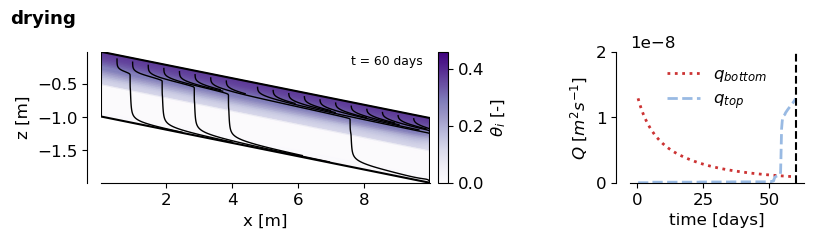

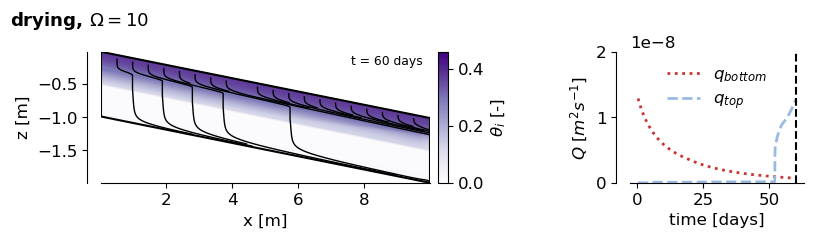

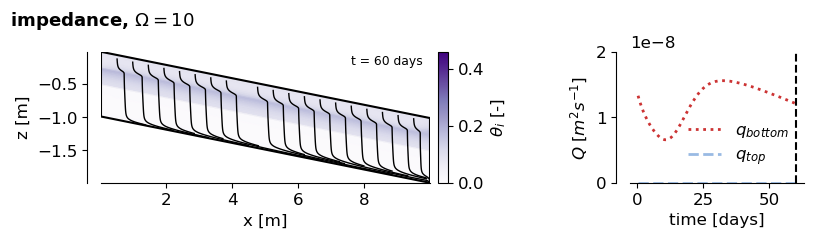

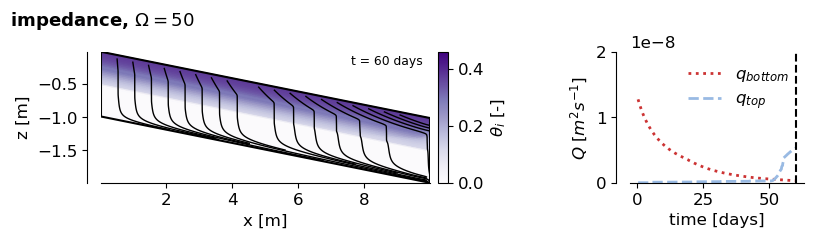

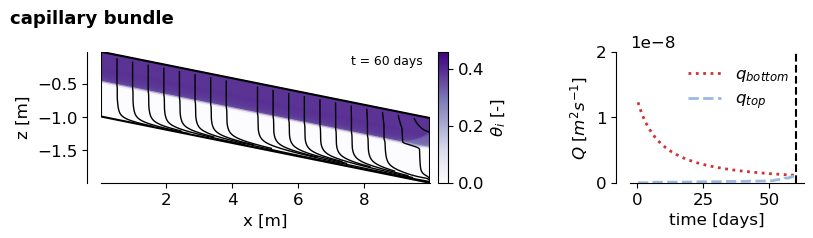

In [4]:
for parametrization, db in constant_dbs.items():
    fig, axes = plotting_utils.plot_interflow_streamlines(db, parametrization, index, slope=-0.1, ylim=(0,2e-8))
    fig.savefig(f"../figures/Simulations_Paper/Constant/constant_{parametrization}.png", dpi=300)


## Cumulative partitioning comparison across parametrizations

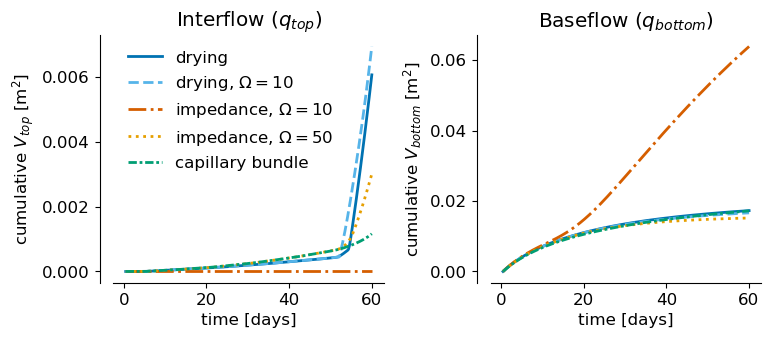

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(20*plotting_utils.cm, 9*plotting_utils.cm))
plotting_utils.plot_cumulative_interflow_comparison(constant_dbs, quantity="top", relative=False,
                                         title="Interflow ($q_{top}$)", fig=fig, ax=axes[0],legend = True)
plotting_utils.plot_cumulative_interflow_comparison(constant_dbs, quantity="bottom", relative=False,
                                         title="Baseflow ($q_{bottom}$)", fig=fig, ax=axes[1])

fig.tight_layout()
fig.savefig("../figures/Simulations_Paper/Constant/const_cum_flow.png", dpi=300)


# ERA5-Land BC Simulation

In [14]:
input_folder = '../output/Simulations_Paper/ERA5_Sweden/simulations/horton/simulation_'
# input_folder = '../output/Simulations_Paper/Constant/Interpolation/'

In [17]:
index = 105

era5_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "permaFoam_omega10": "permaFoam_omega10.pkl",
    "permaFoam_omega50": "permaFoam_omega50.pkl",
    # "cap": "cap.pkl",
}

era5_dbs = {}
for parametrization, filename in era5_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        era5_dbs[parametrization] = pickle.load(pickle_file)


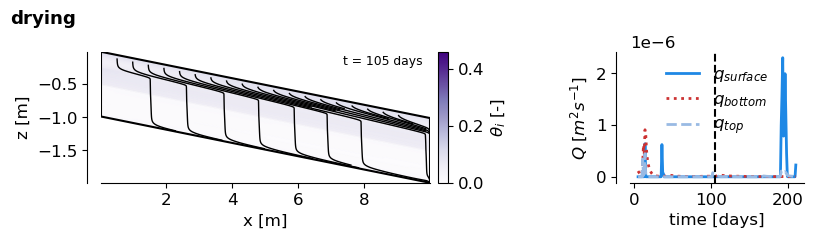

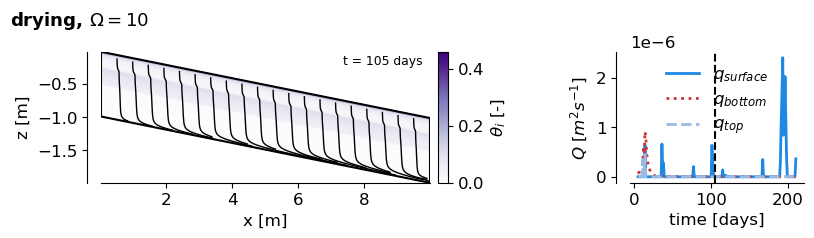

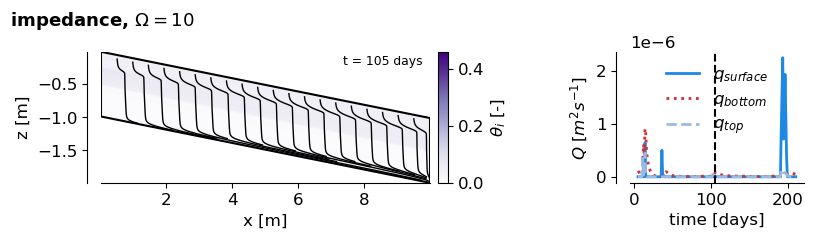

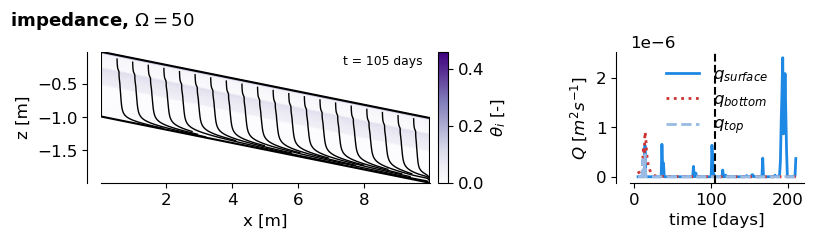

In [18]:
for parametrization, db in era5_dbs.items():
    fig, axes = plotting_utils.plot_interflow_streamlines(db, parametrization, index, slope=-0.1)
    # fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/sim_7d_{parametrization}.png", dpi=300)


## Cumulative partitioning comparison across parametrizations

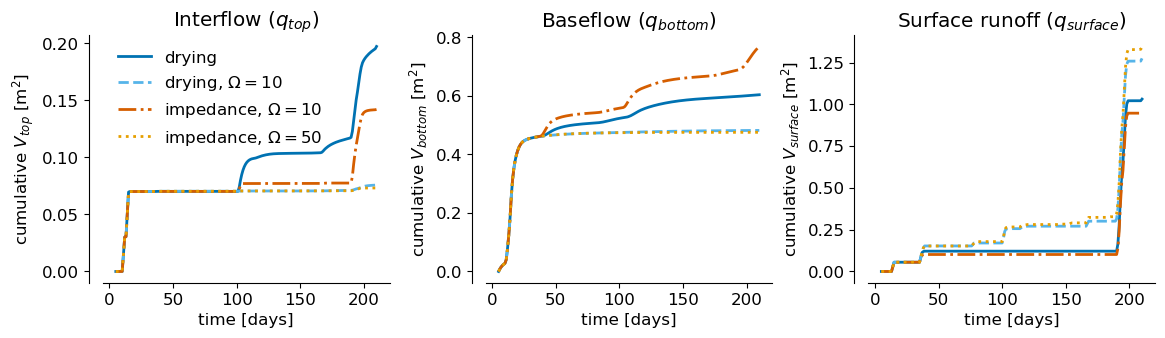

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(30*plotting_utils.cm, 9*plotting_utils.cm))
plotting_utils.plot_cumulative_interflow_comparison(era5_dbs, quantity="top", relative=False,
                                                    title="Interflow ($q_{top}$)", fig=fig, ax=axes[0],legend = True)
plotting_utils.plot_cumulative_interflow_comparison(era5_dbs, quantity="bottom", relative=False,
                                                    title="Baseflow ($q_{bottom}$)", fig=fig, ax=axes[1])
plotting_utils.plot_cumulative_interflow_comparison(era5_dbs, quantity="surf", relative=False,
                                                    title="Surface runoff ($q_{surface}$)", fig=fig, ax=axes[2])
fig.tight_layout()
# fig.savefig("../figures/Simulations_Paper/ERA5_Sweden/sim_cum_flow.png", dpi=300)


# Mechanism: capillary barrier vs. ice lens

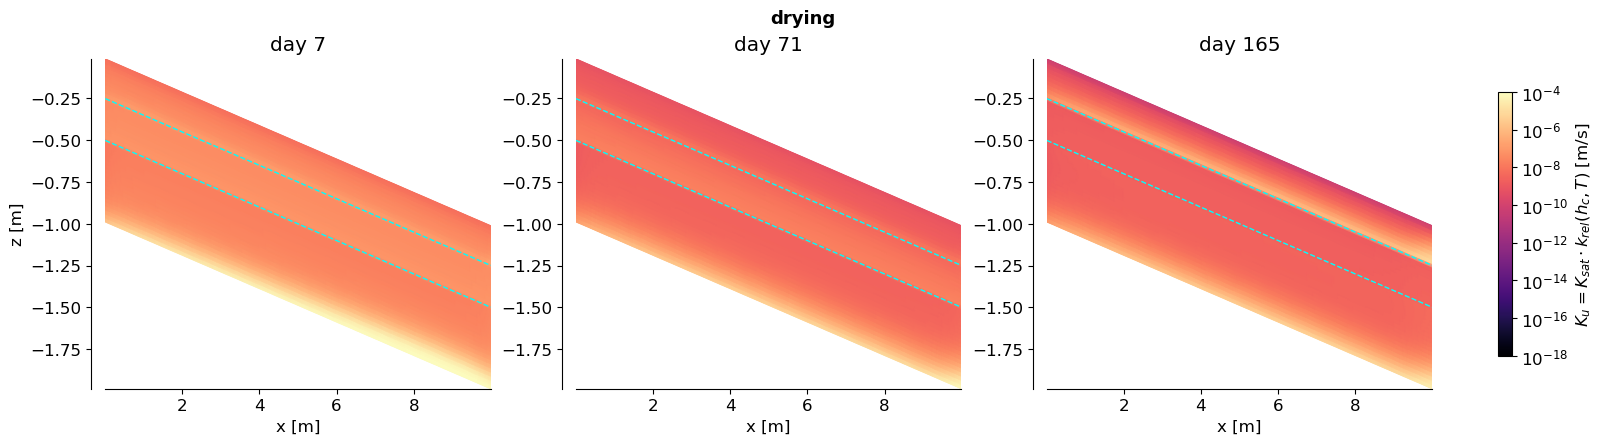

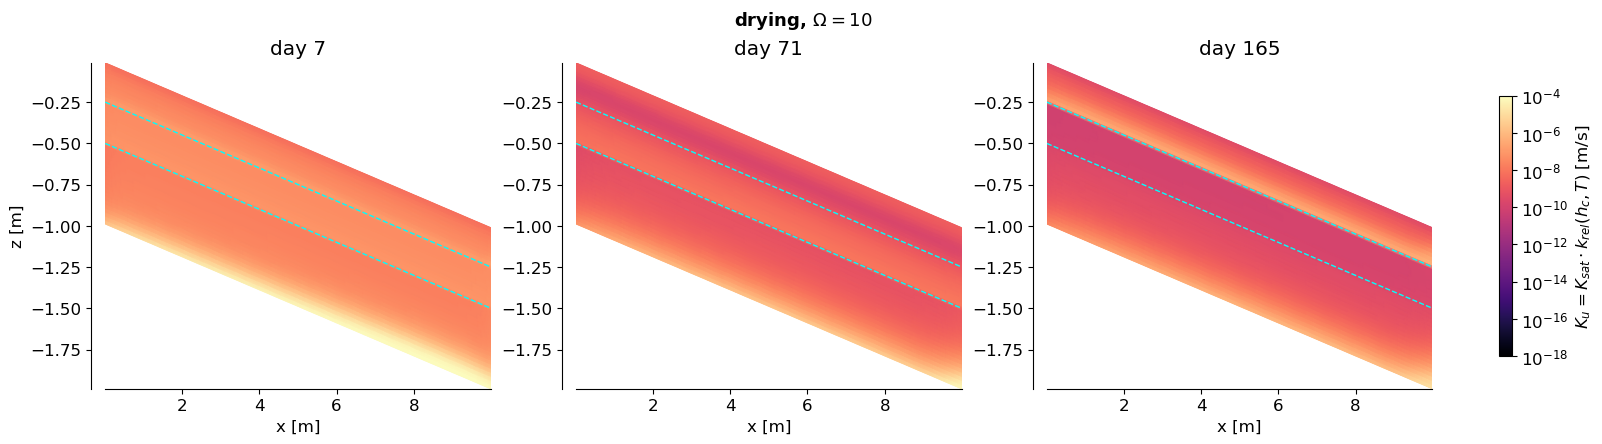

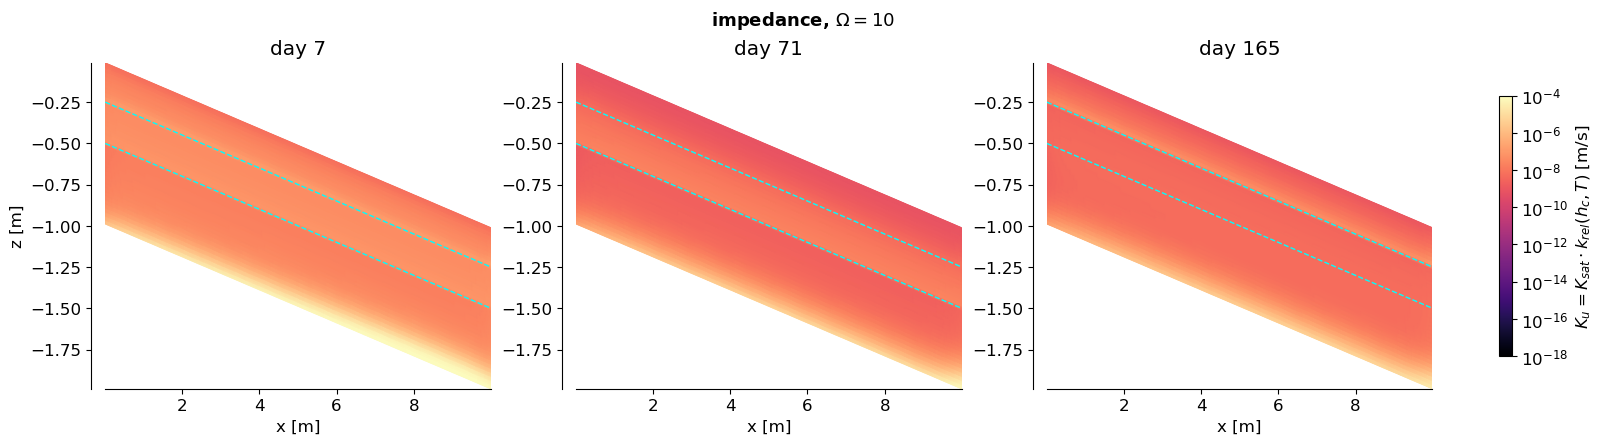

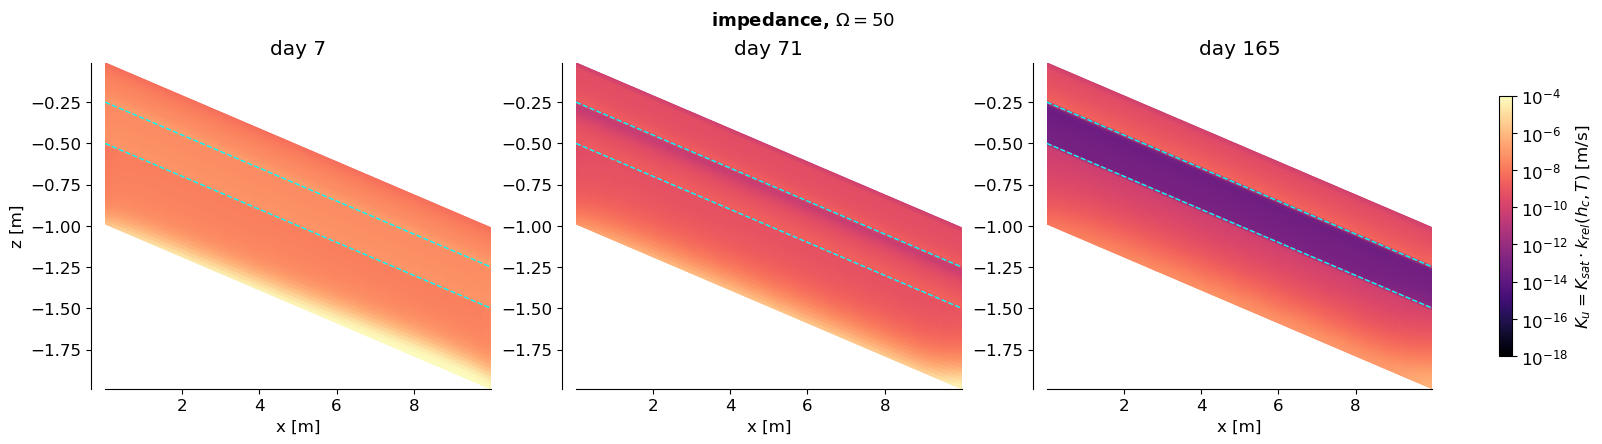

In [10]:
for parametrization, db in era5_dbs.items():
    fig, axes = plotting_utils.plot_Ku(db, parametrization, [7, 71, 165],
                                       interp_folder="../input/interpolation/",
                                       suptitle=plotting_utils.parametrization_label(parametrization))
    # fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/Ku_{parametrization}.png", dpi=300)


# ERA5-Land BC Simulation

In [11]:
input_folder = '../output/Simulations_Paper/ERA5_Sweden/spinup/spinup_'
# input_folder = '../output/Simulations_Paper/Constant/Interpolation/'

In [12]:
index = 7

era5_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "permaFoam_omega10": "permaFoam_omega10.pkl",
    "permaFoam_omega50": "permaFoam_omega50.pkl",
    "cap": "cap.pkl",
}

era5_dbs = {}
for parametrization, filename in era5_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        era5_dbs[parametrization] = pickle.load(pickle_file)


FileNotFoundError: [Errno 2] No such file or directory: '../output/Simulations_Paper/ERA5_Sweden/spinup/spinup_drying.pkl'

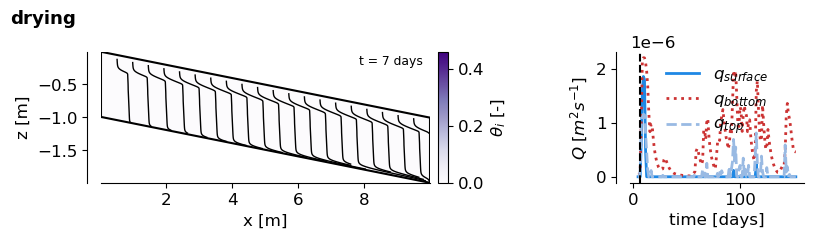

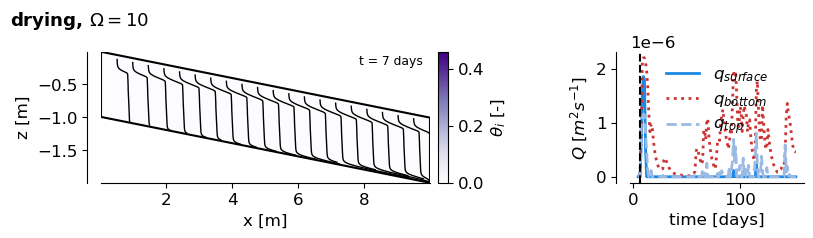

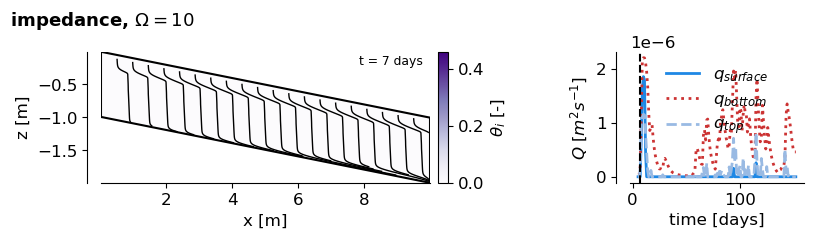

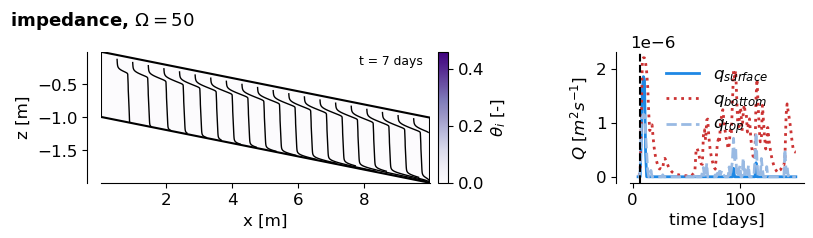

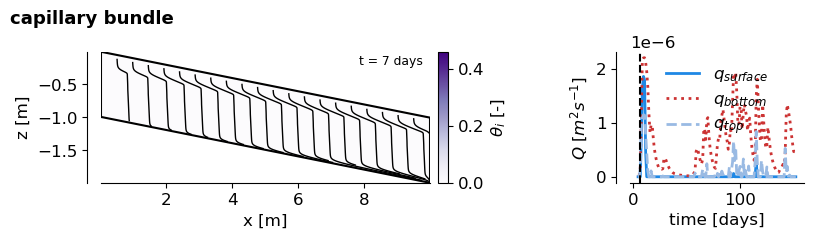

In [ ]:
for parametrization, db in era5_dbs.items():
    fig, axes = plotting_utils.plot_interflow_streamlines(db, parametrization, index, slope=-0.1)
    # fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/sim_7d_{parametrization}.png", dpi=300)


## Cumulative partitioning comparison across parametrizations

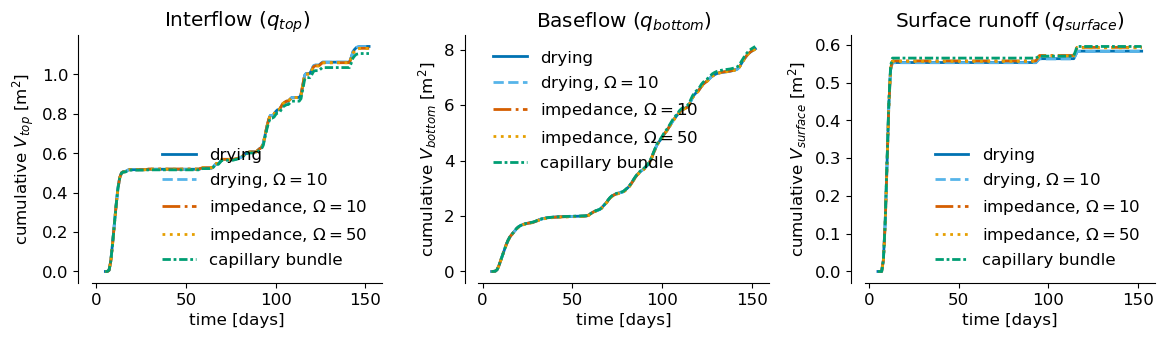

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(30*plotting_utils.cm, 9*plotting_utils.cm))
plotting_utils.plot_cumulative_interflow_comparison(era5_dbs, quantity="top", relative=False,
                                                    title="Interflow ($q_{top}$)", fig=fig, ax=axes[0])
plotting_utils.plot_cumulative_interflow_comparison(era5_dbs, quantity="bottom", relative=False,
                                                    title="Baseflow ($q_{bottom}$)", fig=fig, ax=axes[1])
plotting_utils.plot_cumulative_interflow_comparison(era5_dbs, quantity="surf", relative=False,
                                                    title="Surface runoff ($q_{surface}$)", fig=fig, ax=axes[2])
fig.tight_layout()
fig.savefig("../figures/Simulations_Paper/ERA5_Sweden/cumulative_partitioning_comparison.png", dpi=300)
